In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:

df = pd.read_csv("CC GENERAL.csv")

features = df[["BALANCE", "PURCHASES"]].copy()

print(features.head())
print("Shape:", features.shape)

       BALANCE  PURCHASES
0    40.900749      95.40
1  3202.467416       0.00
2  2495.148862     773.17
3  1666.670542    1499.00
4   817.714335      16.00
Shape: (8950, 2)


In [4]:
valid_mask = np.isfinite(features["BALANCE"]) & np.isfinite(features["PURCHASES"])

filtered = features.loc[valid_mask].copy()

print("Original rows:", len(features))
print("Rows after validity filtering:", len(filtered))
print("Rows removed:", len(features) - len(filtered))

Original rows: 8950
Rows after validity filtering: 8950
Rows removed: 0


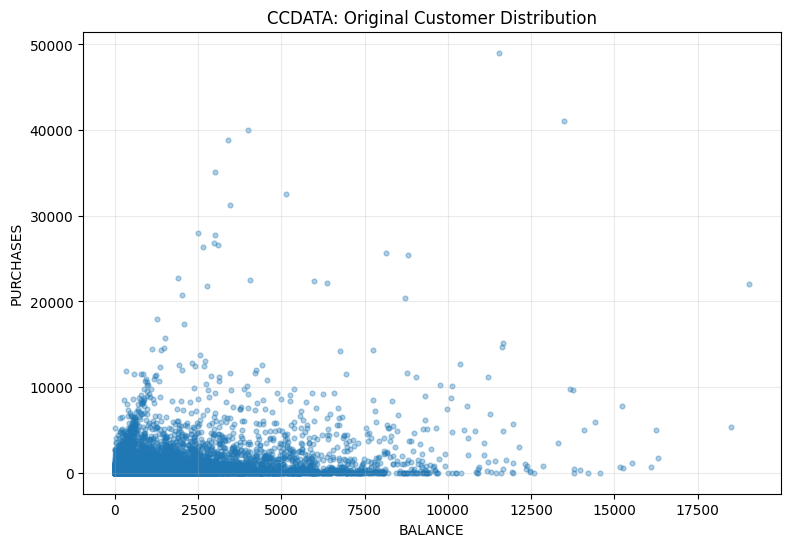

In [5]:
plt.figure(figsize=(9, 6))

plt.scatter(
    features["BALANCE"],
    features["PURCHASES"],
    alpha=0.35,
    s=12
)

plt.xlabel("BALANCE")
plt.ylabel("PURCHASES")
plt.title("CCDATA: Original Customer Distribution")
plt.grid(True, alpha=0.25)
plt.show()

In [6]:
required_columns = ["BALANCE", "PURCHASES", "CREDIT_LIMIT"]

df[required_columns] = df[required_columns].replace(
    [np.inf, -np.inf], np.nan
)

clean_df = df.dropna(subset=required_columns).copy()

print("Original rows:", len(df))
print("Rows after validity filtering:", len(clean_df))
print("Rows removed:", len(df) - len(clean_df))

Original rows: 8950
Rows after validity filtering: 8949
Rows removed: 1


In [7]:
credit_threshold = clean_df["CREDIT_LIMIT"].quantile(0.70)
purchase_threshold = clean_df["PURCHASES"].quantile(0.70)

clean_df["CLASS"] = (
    (clean_df["CREDIT_LIMIT"] >= credit_threshold) &
    (clean_df["PURCHASES"] >= purchase_threshold)
).astype(int)

print("Credit limit threshold:", credit_threshold)
print("Purchase threshold:", purchase_threshold)
print("\nClass counts:")
print(clean_df["CLASS"].value_counts().sort_index())

Credit limit threshold: 6000.0
Purchase threshold: 894.3519999999999

Class counts:
CLASS
0    7671
1    1278
Name: count, dtype: int64


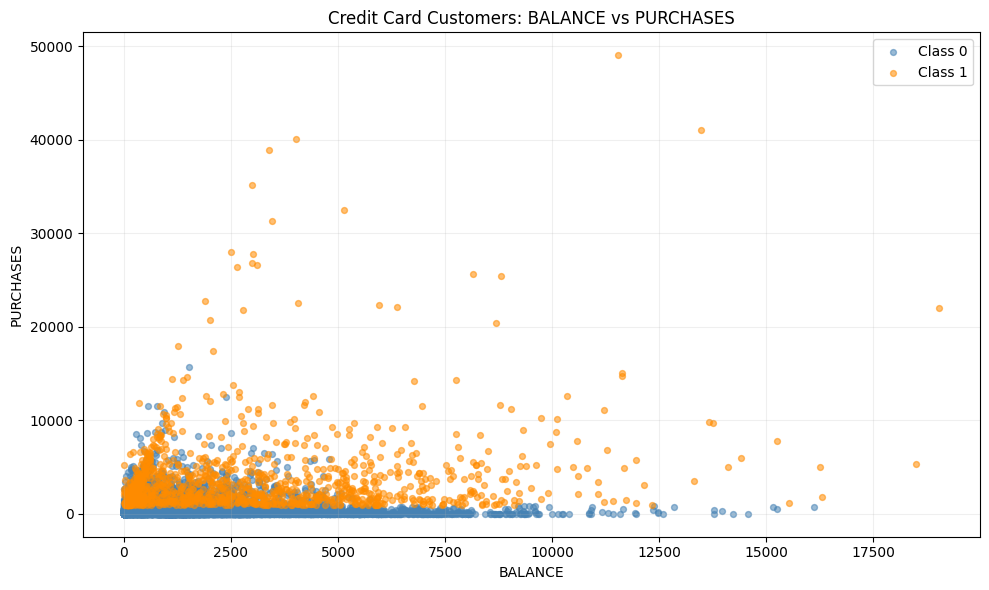

In [8]:
plt.figure(figsize=(10, 6))

for label, color in [(0, "steelblue"), (1, "darkorange")]:
    subset = clean_df[clean_df["CLASS"] == label]

    plt.scatter(
        subset["BALANCE"],
        subset["PURCHASES"],
        color=color,
        label=f"Class {label}",
        alpha=0.55,
        s=18
    )

plt.xlabel("BALANCE")
plt.ylabel("PURCHASES")
plt.title("Credit Card Customers: BALANCE vs PURCHASES")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [9]:
import numpy as np
import matplotlib.pyplot as plt

features = df[["BALANCE", "PURCHASES"]].copy()
features = features.replace([np.inf, -np.inf], np.nan)
features = features.dropna().copy()

df = df.loc[features.index].copy()

boundary_slope = 0.5
boundary_intercept = 1000

boundary_value = (
    boundary_slope * features["BALANCE"] + boundary_intercept
)

df["CLASS"] = (
    features["PURCHASES"] > boundary_value
).astype(int)

print(df["CLASS"].value_counts().sort_index())

CLASS
0    7294
1    1656
Name: count, dtype: int64


In [10]:
distance_from_boundary = (
    features["PURCHASES"]
    - boundary_slope * features["BALANCE"]
    - boundary_intercept
)

gap = 500

keep = (
    ((df["CLASS"] == 0) & (distance_from_boundary <= -gap)) |
    ((df["CLASS"] == 1) & (distance_from_boundary >= gap))
)

filtered_features = features.loc[keep].copy()
filtered_classes = df.loc[keep, "CLASS"]

print("Original valid records:", len(features))
print("Retained records:", len(filtered_features))
print("Removed records:", len(features) - len(filtered_features))
print("\nRetained class counts:")
print(filtered_classes.value_counts().sort_index())

Original valid records: 8950
Retained records: 7465
Removed records: 1485

Retained class counts:
CLASS
0    6335
1    1130
Name: count, dtype: int64


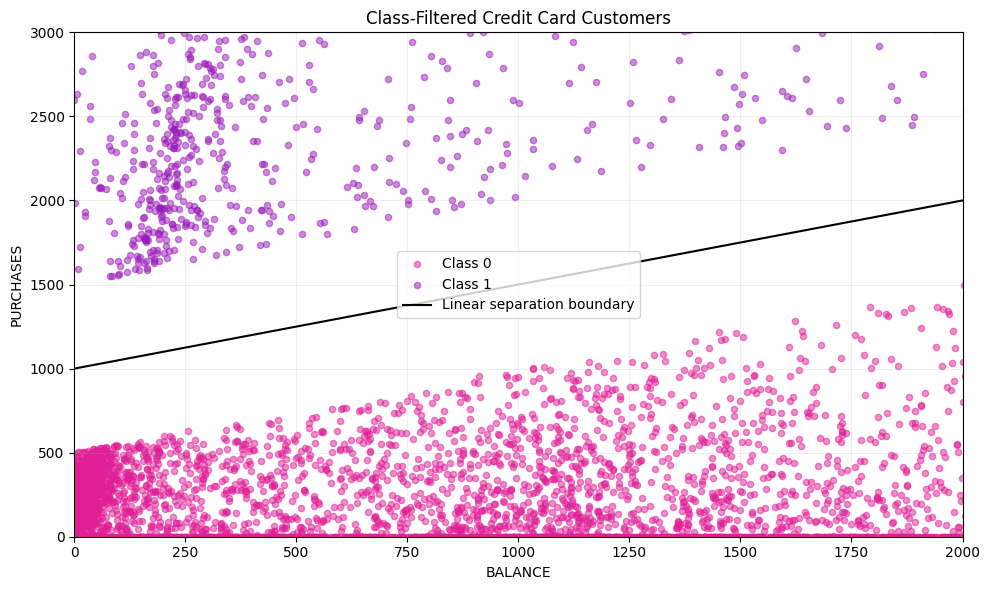

In [11]:
plt.figure(figsize=(10, 6))
for label, color in [(0, "#E01E96"), (1, "#9A1AB9")]:
    subset = filtered_features.loc[filtered_classes == label]

    plt.scatter(
        subset["BALANCE"],
        subset["PURCHASES"],
        color=color,
        label=f"Class {label}",
        alpha=0.5,
        s=20
    )

x_values = np.linspace(
    filtered_features["BALANCE"].min(),
    filtered_features["BALANCE"].max(),
    200
)

plt.plot(
    x_values,
    boundary_slope * x_values + boundary_intercept,
    color="black",
    label="Linear separation boundary"
)

plt.xlabel("BALANCE")
plt.ylabel("PURCHASES")
plt.title("Class-Filtered Credit Card Customers")
plt.legend()
plt.grid(alpha=0.2)
plt.xlim(0, 2000)
plt.ylim(0, 3000)
plt.tight_layout()
plt.show()

In [12]:
import numpy as np
from scipy.optimize import minimize

X = filtered_features[["BALANCE", "PURCHASES"]].to_numpy(dtype=float)
y = np.where(np.asarray(filtered_classes).ravel() == 1, 1, -1)

mean = X.mean(axis=0)
std = X.std(axis=0)
std[std == 0] = 1

X_scaled = (X - mean) / std

C = 1.0

def objective(params):
    w = params[:2]
    b = params[2]

    scores = X_scaled @ w + b
    hinge_loss = np.maximum(0, 1 - y * scores)

    return 0.5 * np.dot(w, w) + C * np.sum(hinge_loss)

def gradient(params):
    w = params[:2]
    b = params[2]

    scores = X_scaled @ w + b
    violating = y * scores < 1

    grad_w = w - C * np.sum(
        y[violating, None] * X_scaled[violating], axis=0
    )
    grad_b = -C * np.sum(y[violating])

    return np.append(grad_w, grad_b)

result = minimize(
    objective,
    np.zeros(3),
    jac=gradient,
    method="L-BFGS-B",
    options={"maxiter": 2000}
)

w = result.x[:2]
b = result.x[2]

print("Weights:", w)
print("Bias:", b)
print("Objective value:", result.fun)
print("Optimizer converged:", result.success)

Weights: [-2.10852763  4.52877323]
Bias: -1.7899004784102472
Objective value: 12.720650570317263
Optimizer converged: True


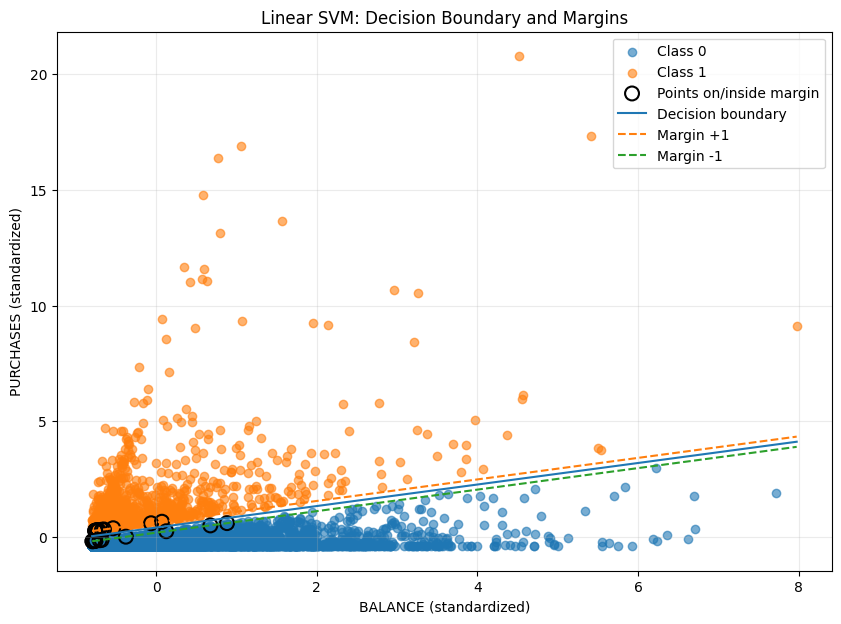

Margin width (standardized space): 0.400355
Points on/inside margin: 27


In [13]:

scores = X_scaled @ w + b
margin_values = y * scores

support_mask = margin_values <= 1 + 1e-4

margin_width = 2 / np.linalg.norm(w)

plt.figure(figsize=(10, 7))

plt.scatter(
    X_scaled[y == -1, 0],
    X_scaled[y == -1, 1],
    label="Class 0",
    alpha=0.6
)

plt.scatter(
    X_scaled[y == 1, 0],
    X_scaled[y == 1, 1],
    label="Class 1",
    alpha=0.6
)

plt.scatter(
    X_scaled[support_mask, 0],
    X_scaled[support_mask, 1],
    s=100,
    facecolors="none",
    edgecolors="black",
    linewidths=1.5,
    label="Points on/inside margin"
)

x_line = np.linspace(
    X_scaled[:, 0].min(),
    X_scaled[:, 0].max(),
    300
)

if abs(w[1]) > 1e-10:
    plt.plot(
        x_line, -(w[0] * x_line + b) / w[1],
        label="Decision boundary"
    )
    plt.plot(
        x_line, -(w[0] * x_line + b - 1) / w[1],
        "--", label="Margin +1"
    )
    plt.plot(
        x_line, -(w[0] * x_line + b + 1) / w[1],
        "--", label="Margin -1"
    )
else:
    plt.axvline(-b / w[0], label="Decision boundary")
    plt.axvline(-(b - 1) / w[0], linestyle="--", label="Margin +1")
    plt.axvline(-(b + 1) / w[0], linestyle="--", label="Margin -1")

plt.xlabel("BALANCE (standardized)")
plt.ylabel("PURCHASES (standardized)")
plt.title("Linear SVM: Decision Boundary and Margins")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

print(f"Margin width (standardized space): {margin_width:.6f}")
print(f"Points on/inside margin: {support_mask.sum()}")

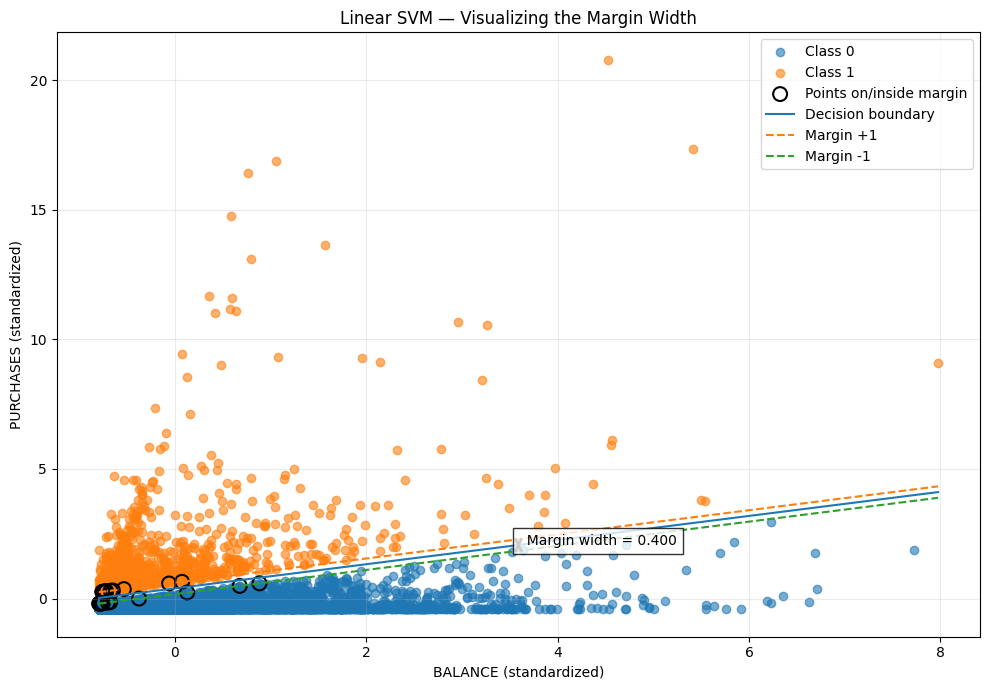

Margin width = 0.4004


In [14]:
fig, ax = plt.subplots(figsize=(10, 7))

ax.scatter(X_scaled[y == -1, 0], X_scaled[y == -1, 1],
           label="Class 0", alpha=0.6)

ax.scatter(X_scaled[y == 1, 0], X_scaled[y == 1, 1],
           label="Class 1", alpha=0.6)

ax.scatter(X_scaled[support_mask, 0], X_scaled[support_mask, 1],
           s=100, facecolors="none", edgecolors="black",
           linewidths=1.5, label="Points on/inside margin")

x_line = np.linspace(X_scaled[:, 0].min(), X_scaled[:, 0].max(), 300)

if abs(w[1]) > 1e-10:
    decision = -(w[0] * x_line + b) / w[1]
    margin_plus = -(w[0] * x_line + b - 1) / w[1]
    margin_minus = -(w[0] * x_line + b + 1) / w[1]

    ax.plot(x_line, decision, label="Decision boundary")
    ax.plot(x_line, margin_plus, "--", label="Margin +1")
    ax.plot(x_line, margin_minus, "--", label="Margin -1")

    x_mid = np.mean(x_line)
    y_plus = -(w[0] * x_mid + b - 1) / w[1]
    y_minus = -(w[0] * x_mid + b + 1) / w[1]

    ax.annotate(
        "",
        xy=(x_mid, y_plus),
        xytext=(x_mid, y_minus),
        arrowprops=dict(arrowstyle="<->", color="black", linewidth=2)
    )

    ax.text(
        x_mid, (y_plus + y_minus) / 2,
        f"  Margin width = {2 / np.linalg.norm(w):.3f}",
        fontsize=10,
        bbox=dict(facecolor="white", alpha=0.8)
    )

else:
    boundary_x = -b / w[0]
    plus_x = -(b - 1) / w[0]
    minus_x = -(b + 1) / w[0]

    ax.axvline(boundary_x, label="Decision boundary")
    ax.axvline(plus_x, linestyle="--", label="Margin +1")
    ax.axvline(minus_x, linestyle="--", label="Margin -1")

    y_mid = np.mean(ax.get_ylim())
    ax.annotate(
        "",
        xy=(plus_x, y_mid),
        xytext=(minus_x, y_mid),
        arrowprops=dict(arrowstyle="<->", color="black", linewidth=2)
    )

ax.set_xlabel("BALANCE (standardized)")
ax.set_ylabel("PURCHASES (standardized)")
ax.set_title("Linear SVM — Visualizing the Margin Width")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print(f"Margin width = {2 / np.linalg.norm(w):.4f}")

In [15]:

import numpy as np
from scipy.optimize import minimize

X = filtered_features[["BALANCE", "PURCHASES"]].to_numpy(dtype=float)
y = np.where(np.asarray(filtered_classes).ravel() == 1, 1, -1)

mean = X.mean(axis=0)
std = X.std(axis=0)
std[std == 0] = 1
X_scaled = (X - mean) / std

C_values = [0.1, 1, 10, 100]
trained_models = {}

for C in C_values:

    def objective(params):
        w = params[:2]
        b = params[2]
        scores = X_scaled @ w + b
        hinge_loss = np.maximum(0, 1 - y * scores)
        return 0.5 * np.dot(w, w) + C * np.sum(hinge_loss)

    def gradient(params):
        w = params[:2]
        b = params[2]
        scores = X_scaled @ w + b
        violating = y * scores < 1

        grad_w = w - C * np.sum(
            y[violating, None] * X_scaled[violating],
            axis=0
        )
        grad_b = -C * np.sum(y[violating])

        return np.append(grad_w, grad_b)

    result = minimize(
        objective,
        np.zeros(3),
        jac=gradient,
        method="L-BFGS-B",
        options={"maxiter": 2000}
    )

    if not result.success:
        print(f"C = {C}: Optimization warning - {result.message}")

    trained_models[C] = {
        "weights": result.x[:2],
        "bias": result.x[2],
        "objective_value": result.fun
    }

    print(f"C = {C}")
    print("Weights:", result.x[:2])
    print("Bias:", result.x[2])
    print("Objective value:", result.fun)
    print("-" * 40)


C = 0.1
Weights: [-1.73113507  3.84087474]
Bias: -1.579252152183656
Objective value: 10.682250729147416
----------------------------------------
C = 1
Weights: [-2.10852763  4.52877323]
Bias: -1.7899004784102472
Objective value: 12.720650570317263
----------------------------------------
C = 10
Weights: [-2.15432113  4.60442854]
Bias: -1.816447435715986
Objective value: 12.955746091670914
----------------------------------------
C = 100
Weights: [-2.22483695  4.67161521]
Bias: -1.8576852658499303
Objective value: 13.386944089525318
----------------------------------------


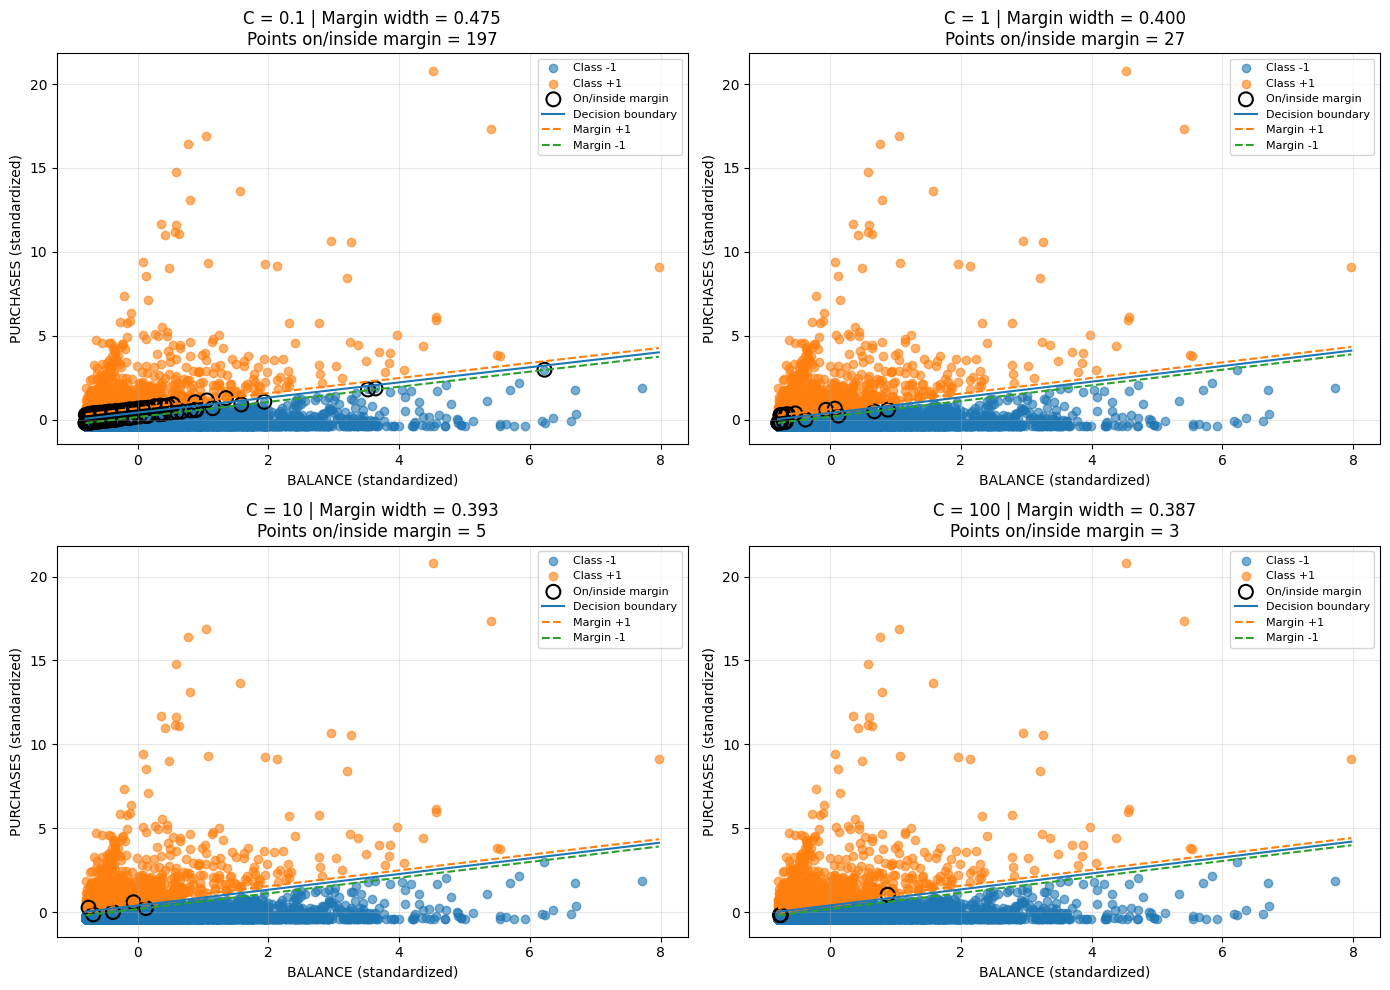

In [16]:

import numpy as np
import matplotlib.pyplot as plt

C_values = [0.1, 1, 10, 100]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()

x_line = np.linspace(
    X_scaled[:, 0].min(),
    X_scaled[:, 0].max(),
    300
)

for ax, C in zip(axes, C_values):
    w = trained_models[C]["weights"]
    b = trained_models[C]["bias"]

    scores = X_scaled @ w + b
    margin_values = y * scores

    support_mask = margin_values <= 1 + 1e-4

    ax.scatter(
        X_scaled[y == -1, 0],
        X_scaled[y == -1, 1],
        label="Class -1",
        alpha=0.6
    )

    ax.scatter(
        X_scaled[y == 1, 0],
        X_scaled[y == 1, 1],
        label="Class +1",
        alpha=0.6
    )

    ax.scatter(
        X_scaled[support_mask, 0],
        X_scaled[support_mask, 1],
        s=100,
        facecolors="none",
        edgecolors="black",
        linewidths=1.5,
        label="On/inside margin"
    )

    if abs(w[1]) > 1e-10:
        decision = -(w[0] * x_line + b) / w[1]
        margin_plus = -(w[0] * x_line + b - 1) / w[1]
        margin_minus = -(w[0] * x_line + b + 1) / w[1]

        ax.plot(x_line, decision, label="Decision boundary")
        ax.plot(x_line, margin_plus, "--", label="Margin +1")
        ax.plot(x_line, margin_minus, "--", label="Margin -1")
    else:
        ax.axvline(-b / w[0], label="Decision boundary")
        ax.axvline(-(b - 1) / w[0], linestyle="--", label="Margin +1")
        ax.axvline(-(b + 1) / w[0], linestyle="--", label="Margin -1")

    margin_width = 2 / np.linalg.norm(w)

    ax.set_title(
        f"C = {C} | Margin width = {margin_width:.3f}\n"
        f"Points on/inside margin = {support_mask.sum()}"
    )
    ax.set_xlabel("BALANCE (standardized)")
    ax.set_ylabel("PURCHASES (standardized)")
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


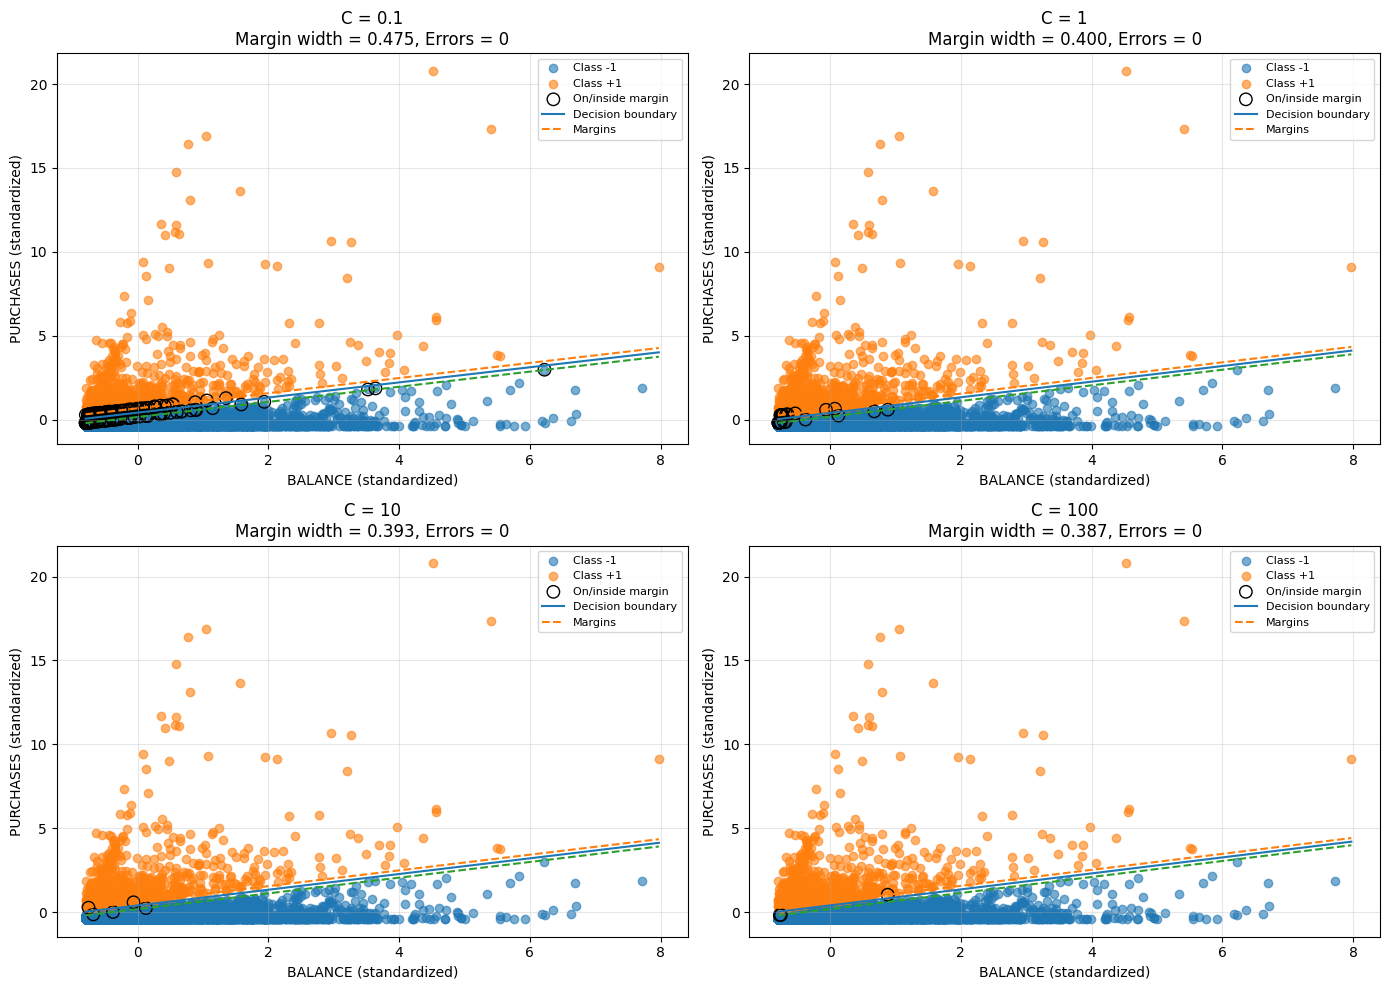

    C  Margin Width  Classification Errors  Hinge Loss
  0.1      0.474724                      0   18.076770
  1.0      0.400355                      0    0.242813
 10.0      0.393431                      0    0.003482
100.0      0.386522                      0    0.000000


In [17]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

C_values = [0.1, 1, 10, 100]
results = []

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()

x_line = np.linspace(X_scaled[:, 0].min(), X_scaled[:, 0].max(), 300)

for ax, C in zip(axes, C_values):

    def objective(params):
        w = params[:2]
        b = params[2]
        scores = X_scaled @ w + b
        hinge_loss = np.maximum(0, 1 - y * scores)
        return 0.5 * np.dot(w, w) + C * np.sum(hinge_loss)

    def gradient(params):
        w = params[:2]
        b = params[2]
        scores = X_scaled @ w + b
        violating = y * scores < 1

        grad_w = w - C * np.sum(
            y[violating, None] * X_scaled[violating], axis=0
        )
        grad_b = -C * np.sum(y[violating])

        return np.append(grad_w, grad_b)

    result = minimize(
        objective,
        np.zeros(3),
        jac=gradient,
        method="L-BFGS-B",
        options={"maxiter": 2000}
    )

    w = result.x[:2]
    b = result.x[2]

    scores = X_scaled @ w + b
    margin_values = y * scores
    predictions = np.where(scores >= 0, 1, -1)

    errors = np.sum(predictions != y)
    margin_width = 2 / np.linalg.norm(w)
    hinge_loss = np.maximum(0, 1 - margin_values).sum()

    results.append({
        "C": C,
        "Margin Width": margin_width,
        "Classification Errors": errors,
        "Hinge Loss": hinge_loss
    })

    support_mask = margin_values <= 1 + 1e-4

    ax.scatter(
        X_scaled[y == -1, 0], X_scaled[y == -1, 1],
        label="Class -1", alpha=0.6
    )
    ax.scatter(
        X_scaled[y == 1, 0], X_scaled[y == 1, 1],
        label="Class +1", alpha=0.6
    )
    ax.scatter(
        X_scaled[support_mask, 0], X_scaled[support_mask, 1],
        facecolors="none", edgecolors="black", s=80,
        label="On/inside margin"
    )

    if abs(w[1]) > 1e-10:
        decision = -(w[0] * x_line + b) / w[1]
        margin_plus = -(w[0] * x_line + b - 1) / w[1]
        margin_minus = -(w[0] * x_line + b + 1) / w[1]

        ax.plot(x_line, decision, label="Decision boundary")
        ax.plot(x_line, margin_plus, "--", label="Margins")
        ax.plot(x_line, margin_minus, "--")
    else:
        ax.axvline(-b / w[0], label="Decision boundary")
        ax.axvline(-(b - 1) / w[0], linestyle="--", label="Margins")
        ax.axvline(-(b + 1) / w[0], linestyle="--")

    ax.set_title(
        f"C = {C}\nMargin width = {margin_width:.3f}, Errors = {errors}"
    )
    ax.set_xlabel("BALANCE (standardized)")
    ax.set_ylabel("PURCHASES (standardized)")
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))


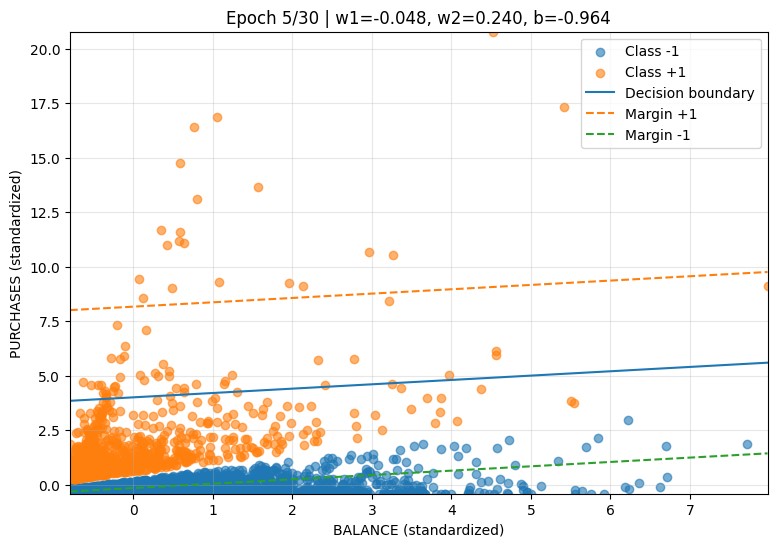

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, clear_output
import time

w = np.zeros(2)
b = 0.0

learning_rate = 0.001
C = 1.0
epochs = 30

x_min, x_max = X_scaled[:, 0].min(), X_scaled[:, 0].max()
y_min, y_max = X_scaled[:, 1].min(), X_scaled[:, 1].max()

x_line = np.linspace(x_min, x_max, 300)

fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(
    X_scaled[y == -1, 0],
    X_scaled[y == -1, 1],
    label="Class -1",
    alpha=0.6
)

ax.scatter(
    X_scaled[y == 1, 0],
    X_scaled[y == 1, 1],
    label="Class +1",
    alpha=0.6
)

boundary_line, = ax.plot([], [], label="Decision boundary")
margin_plus_line, = ax.plot([], [], "--", label="Margin +1")
margin_minus_line, = ax.plot([], [], "--", label="Margin -1")

ax.set_xlim(x_min, x_max)
ax.set_ylim(y_min, y_max)
ax.set_xlabel("BALANCE (standardized)")
ax.set_ylabel("PURCHASES (standardized)")
ax.legend()
ax.grid(True, alpha=0.3)

for epoch in range(epochs):
    for i in range(len(X_scaled)):
        x_i = X_scaled[i]
        y_i = y[i]

        if y_i * (np.dot(w, x_i) + b) < 1:
            w = w - learning_rate * (w - C * y_i * x_i)
            b = b + learning_rate * C * y_i
        else:
            w = w - learning_rate * w

        if abs(w[1]) > 1e-10:
            decision = -(w[0] * x_line + b) / w[1]
            margin_plus = -(w[0] * x_line + b - 1) / w[1]
            margin_minus = -(w[0] * x_line + b + 1) / w[1]

            boundary_line.set_data(x_line, decision)
            margin_plus_line.set_data(x_line, margin_plus)
            margin_minus_line.set_data(x_line, margin_minus)

        ax.set_title(
            f"Epoch {epoch + 1}/{epochs} | "
            f"w1={w[0]:.3f}, w2={w[1]:.3f}, b={b:.3f}"
        )

        clear_output(wait=True)
        display(fig)
        time.sleep(0.02)

plt.close(fig)